PyTorch: 2.11.0+cu130 | OpenCV: 5.0.0 | Urządzenie: cuda
Utworzono zbiór: dane_demo
  kolo: 60 obrazów
  kwadrat: 60 obrazów

Klasy: ['kolo', 'kwadrat'] -> indeksy: {'kolo': 0, 'kwadrat': 1}
Liczba wszystkich przykładów: 120
Kształt paczki obrazów: torch.Size([16, 3, 64, 64]) | Etykiety: [1 0 1 1 0 1 0 0]


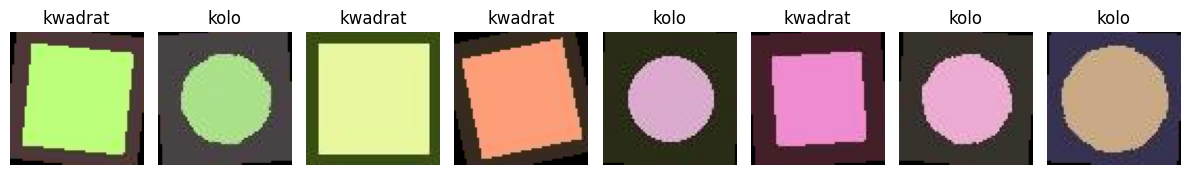


--- Test przetwarzania wideo ---
Przekształcony tensor wideo (klatki, kanały, wys, szer): torch.Size([4, 3, 64, 64])


In [1]:
import os
import urllib.request
import numpy as np
import cv2
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt


torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch: {torch.__version__} | OpenCV: {cv2.__version__} | Urządzenie: {device}")


ROOT = "dane_demo"
classes_demo = ["kolo", "kwadrat"]
N_PER_CLASS = 60

def make_image(kind, size=64):
    bg = tuple(int(x) for x in np.random.randint(20, 80, size=3))
    img = Image.new("RGB", (size, size), bg)
    d = ImageDraw.Draw(img)
    color = tuple(int(x) for x in np.random.randint(120, 255, size=3))
    m = np.random.randint(6, 14)
    box = [m, m, size - m, size - m]
    if kind == "kolo":
        d.ellipse(box, fill=color)
    else:
        d.rectangle(box, fill=color)
    return img

for c in classes_demo:
    os.makedirs(f"{ROOT}/{c}", exist_ok=True)
    for i in range(N_PER_CLASS):
        make_image(c).save(f"{ROOT}/{c}/{c}_{i:03d}.jpg")

print(f"Utworzono zbiór: {ROOT}")
for c in classes_demo:
    print(f"  {c}: {len(os.listdir(f'{ROOT}/{c}'))} obrazów")


data_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


dataset = datasets.ImageFolder(root=ROOT, transform=data_transforms)
dataloader = DataLoader(dataset, batch_size=16, shuffle=True)

print(f"\nKlasy: {dataset.classes} -> indeksy: {dataset.class_to_idx}")
print(f"Liczba wszystkich przykładów: {len(dataset)}")


images, labels = next(iter(dataloader))
print(f"Kształt paczki obrazów: {images.shape} | Etykiety: {labels.numpy()[:8]}")


def imshow_tensor(tensor_img, title=None):

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor_img.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    if title:
        plt.title(title)
    plt.axis('off')

fig = plt.figure(figsize=(12, 3))
for i in range(8):
    ax = fig.add_subplot(1, 8, i + 1)
    imshow_tensor(images[i], title=dataset.classes[labels[i]])
plt.tight_layout()
plt.show()


def process_video_frames(video_path, transform, max_frames=5):
    """
    Otwiera plik wideo, pobiera klatki, przekształca BGR (OpenCV) na RGB (PIL)
    i przepuszcza przez ten sam potok transformacji PyTorch.
    """
    cap = cv2.VideoCapture(video_path)
    frames_tensors = []

    if not cap.isOpened():
        print(f"Nie udało się otworzyć wideo: {video_path}")
        return None

    frame_count = 0
    while cap.isOpened() and frame_count < max_frames:
        ret, frame = cap.read()
        if not ret:
            break


        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(frame_rgb)


        tensor_frame = transform(pil_img)
        frames_tensors.append(tensor_frame)
        frame_count += 1

    cap.release()

    return torch.stack(frames_tensors)

print("\n--- Test przetwarzania wideo ---")

demo_video_path = "demo_video.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(demo_video_path, fourcc, 10.0, (64, 64))

for _ in range(20):

    img_pil = make_image("kolo", size=64)
    frame_np = cv2.cvtColor(np.array(img_pil), cv2.COLOR_RGB2BGR)
    out.write(frame_np)
out.release()


video_tensor = process_video_frames(demo_video_path, data_transforms, max_frames=4)
print(f"Przekształcony tensor wideo (klatki, kanały, wys, szer): {video_tensor.shape}")